# **Aprendizaje por refuerzos** - LunarLander (Gymnasium)

## Implementación de un agente DQN (Deep Q-Network): consigna

> **Cómo trabajar este cuaderno.** Hay **3 bloques marcados con `TODO`** repartidos
> por las secciones 6 a 11. Cada uno corta la ejecución con `NotImplementedError`
> hasta que lo completen. Todo lo demás (el entorno, la interfaz, las funciones de
> evaluación y entrenamiento, las gráficas de progreso y el GIF de la sección 9) ya
> está escrito y no hay que tocarlo.

> **Qué se entrega.** Este cuaderno completo y autocontenido, con el código y la
> salida de los experimentos realizados, y un **artículo en formato IEEE** de no más
> de 5 páginas con el informe. La discusión de los resultados va en el artículo, no
> en el cuaderno: la letra de la tarea detalla los puntos que tiene que cubrir.

### Objetivos:
1. Explorar el entorno `LunarLander-v3` de Gymnasium (estado continuo, acciones discretas)
2. Testear el agente aleatorio como implementación de referencia
3. Diseñar e implementar un agente DQN
4. Entrenar y evaluar el agente
5. Comparar el desempeño contra la implementación de referencia y visualizar la política aprendida
6. Medir con un estudio de ablación cuánto aporta cada componente de DQN

El requisito mínimo de la consigna es superar **10% de éxito** en evaluación.

El cuaderno se organiza en una interfaz `Agente`, las funciones `entrenar_agente` /
`evaluar_agente` y el agente DQN, aplicados a un problema de **estado continuo**.

## 1. Dependencias

| Paquete | Uso |
|---|---|
| `gymnasium[box2d]` | entorno `LunarLander-v3` (el extra `[box2d]` instala también el motor de física) |
| `torch` | red neuronal Q y optimización |
| `matplotlib` | gráficas de progreso y GIF de la política final |

In [63]:
# Instalar los paquetes necesarios. %pip instala en el kernel que está corriendo.
import os
import sys

# >=1.0 porque LunarLander-v3 existe desde ahí; las anteriores registran solo v2.
%pip install -q "gymnasium[box2d]>=1.0" matplotlib
# Aparte y con --index-url para traer la versión de CPU de torch (≈200 MB) y no la
# de CUDA, que es la que pip elegiría por omisión en Linux.
%pip install -q torch --index-url https://download.pytorch.org/whl/cpu

# Sin pantalla (contenedores, CI) SDL necesita este controlador de video para
# poder dibujar los fotogramas del GIF de la sección 9.
if sys.platform.startswith('linux') and not os.environ.get('DISPLAY'):
    os.environ['SDL_VIDEODRIVER'] = 'dummy'

print(f"kernel: {sys.executable}")

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
kernel: /usr/bin/python3


In [64]:
# Importar las bibliotecas
import random
import time
from abc import ABC, abstractmethod
from collections import deque, namedtuple

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

print(f"gymnasium {gym.__version__} | torch {torch.__version__} | "
      f"dispositivo: {'cuda' if torch.cuda.is_available() else 'cpu'}")

gymnasium 1.4.0 | torch 2.14.1+cpu | dispositivo: cpu


## 2. El entorno LunarLander-v3

El objetivo es posar el módulo lunar sobre la plataforma de aterrizaje (siempre en
las coordenadas `(0, 0)`) de forma suave y sin volcarlo.

**Espacio de observación** (`Box(8,)`, continuo):

| Índice | Variable | Significado | Rango |
|---|---|---|---|
| 0 | `x` | posición horizontal respecto de la plataforma | ±2.5 |
| 1 | `y` | altura respecto de la plataforma | ±2.5 |
| 2 | `vx` | velocidad horizontal | ±10 |
| 3 | `vy` | velocidad vertical | ±10 |
| 4 | `θ` | ángulo del módulo | ±2π |
| 5 | `ω` | velocidad angular | ±10 |
| 6 | `c_izq` | 1 si la pata izquierda toca el suelo | 0 o 1 |
| 7 | `c_der` | 1 si la pata derecha toca el suelo | 0 o 1 |

**Espacio de acciones** (`Discrete(4)`): `0` no hacer nada, `1` motor lateral
izquierdo, `2` motor principal, `3` motor lateral derecho.

**Recompensa**, `+10` por cada pata en contacto con el suelo, `−0.3` por cada paso en que se enciende
el motor principal y `−0.03` por cada paso en que se enciende uno lateral. Al final,
`+100` o `−100` según cómo termine el episodio.

**Fin del episodio.** Hay dos casos:

* **Termina** cuando el módulo se estrella o sale de la pantalla (`|x| ≥ 1`), lo que
  da `−100`, o cuando queda quieto sobre el suelo, lo que da `+100`.
* **Se trunca** a los 1000 pasos, por el límite de tiempo que `gym.make` agrega con
  el *wrapper* `TimeLimit`. Truncar no significa que el episodio haya terminado mal:
  simplemente se acabó el presupuesto.

**Criterio de éxito.** La documentación considera resuelto un episodio que acumula
**al menos 200 puntos**. Se usa ese umbral para definir la *tasa de éxito*
(proporción de episodios con recompensa ≥ 200), que es la métrica que se reporta.

In [65]:
# Explorar el entorno LunarLander
env = gym.make('LunarLander-v3')

print("Información del entorno LunarLander-v3:")
print(f"Espacio de observación: {env.observation_space}")
print(f"Espacio de acción:      {env.action_space}")
print(f"Rango de observación:   {env.observation_space.low}")
print(f"                        {env.observation_space.high}")

estado, _ = env.reset(seed=SEMILLA)
print(f"\nEstado inicial: {np.round(estado, 3)}")
print(f"Forma del estado: {estado.shape}, tipo: {estado.dtype}")

accion = env.action_space.sample()
siguiente_estado, recompensa, terminado, truncado, info = env.step(accion)
print(f"\nAcción aleatoria: {accion}")
print(f"Estado siguiente: {np.round(siguiente_estado, 3)}")
print(f"Recompensa: {recompensa:.3f}")
print(f"Terminado: {terminado}, Truncado: {truncado}")

env.close()

Información del entorno LunarLander-v3:
Espacio de observación: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Espacio de acción:      Discrete(4)
Rango de observación:   [ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ]
                        [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ]

Estado inicial: [ 0.002  1.418  0.233  0.32  -0.003 -0.053  0.     0.   ]
Forma del estado: (8,), tipo: float32

Acción aleatoria: 0
Estado siguiente: [ 0.005  1.425  0.232  0.295 -0.005 -0.052  0.     0.   ]
Recompensa: 1.145
Terminado: False, Truncado: False


La celda siguiente permite jugar el entorno con el teclado: **W/↑** enciende el motor
principal, **A/←** y **D/→** mueven a los costados, **Q** o **ESC** salen. Sirve
para entender la complejidad del problema.

La llamada queda comentada porque es un bucle que no termina solo: hay que
descomentarla a mano.

In [ ]:
def jugar_lunar_lander():
    """Juego interactivo. Controles: W/↑ motor principal, A/← mover a la izquierda,
    D/→ mover a la derecha, ninguna tecla = sin empuje, Q/ESC salir.
    """
    import pygame

    pygame.display.quit()           # obliga a SDL a releer el controlador al reiniciar
    pygame.display.init()
    if pygame.display.get_driver() in ('dummy', 'offscreen'):
        raise RuntimeError(
            'SDL no encontró pantalla. Sin ventana el bucle no recibiría teclas y '
            'colgaría el kernel: hay que correr esta celda en Jupyter local.')

    env = gym.make('LunarLander-v3', render_mode='human')
    env.reset(seed=SEMILLA)
    reloj = pygame.time.Clock()
    recompensa_total = 0.0
    ejecutando = True

    try:
        while ejecutando:
            for evento in pygame.event.get():
                if evento.type == pygame.QUIT or (
                        evento.type == pygame.KEYDOWN
                        and evento.key in (pygame.K_q, pygame.K_ESCAPE)):
                    ejecutando = False

            teclas = pygame.key.get_pressed()
            if teclas[pygame.K_a] or teclas[pygame.K_LEFT]:
                accion = 3                      # motor izq
            elif teclas[pygame.K_d] or teclas[pygame.K_RIGHT]:
                accion = 1                      # motor der
            elif teclas[pygame.K_w] or teclas[pygame.K_UP]:
                accion = 2                      # motor principal
            else:
                accion = 0                      # no hacer nada

            _, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                print(f"Episodio terminado. Recompensa total: {recompensa_total:.1f}")
                recompensa_total = 0.0
                env.reset()

            reloj.tick(50)
    finally:
        env.close()
        pygame.quit()


# Descomentar para jugar (es un bucle interactivo y no termina solo).
# jugar_lunar_lander()

Episodio terminado. Recompensa total: -137.3
Episodio terminado. Recompensa total: -219.3
Episodio terminado. Recompensa total: -250.7
Episodio terminado. Recompensa total: -480.1
Episodio terminado. Recompensa total: -170.3
Episodio terminado. Recompensa total: -5.4
Episodio terminado. Recompensa total: -199.3
Episodio terminado. Recompensa total: -171.7
Episodio terminado. Recompensa total: -123.0
Episodio terminado. Recompensa total: -419.8
Episodio terminado. Recompensa total: -54.1
Episodio terminado. Recompensa total: -248.7
Episodio terminado. Recompensa total: -140.0
Episodio terminado. Recompensa total: -161.6
Episodio terminado. Recompensa total: -201.5


## 3. Interfaz de los agentes

Un agente sabe `elegir_accion` a partir de una observación y `aprender` de una
transición. `elegir_accion` recibe además `explorar`: con `explorar=False` el agente
devuelve la acción que considera mejor, sin exploración; así lo llaman la evaluación
y la grabación del GIF. El agente aleatorio implementa esa interfaz y es la implementación de
referencia contra la que se compara el DQN.

In [67]:
class Agente(ABC):

    @abstractmethod
    def elegir_accion(self, estado, explorar=True):
        """Elige una acción dada una observación. Con `explorar=False`, sin
        exploración: la acción que el agente considera mejor."""
        pass

    @abstractmethod
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Aprende de la experiencia."""
        pass

    def fin_episodio(self):
        """Callback opcional que el bucle de entrenamiento invoca al terminar cada
        episodio."""
        pass


class AgenteAleatorio(Agente):
    """Agente aleatorio que elige acciones al azar. Es la implementación de referencia."""

    def __init__(self, espacio_acciones, semilla=None):
        self.espacio_acciones = espacio_acciones
        if semilla is not None:
            # El espacio de acciones tiene su propio RNG y no lo alcanzan random.seed
            # ni np.random.seed: sin fijarle la semilla acá, el agente aleatorio no es reproducible.
            espacio_acciones.seed(semilla)

    def elegir_accion(self, estado, explorar=True):
        return self.espacio_acciones.sample()   # no tiene otra política que el azar

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        pass  # El agente aleatorio no aprende


# Probar el AgenteAleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
estado, _ = env.reset(seed=SEMILLA)
accion = agente_aleatorio.elegir_accion(estado)
print(f"✓ AgenteAleatorio creado y probado. Acción: {accion}")
env.close()

✓ AgenteAleatorio creado y probado. Acción: 0


## 4. Función de evaluación

`evaluar_agente` corre `num_episodios` episodios completos **sin aprender** y
resume el desempeño. Un episodio se considera **exitoso** si la recompensa
acumulada es **≥ 200**, el umbral de "resuelto" que define Gymnasium para este
entorno.

Las acciones se piden sin exploración (`explorar=False`): la exploración es parte
del entrenamiento, no de la política que se quiere medir.

In [68]:
# Función de evaluación de agentes
UMBRAL_EXITO = 200.0   # recompensa a partir de la cual Gymnasium considera el episodio resuelto


def evaluar_agente(agente, env, num_episodios=100, umbral_exito=UMBRAL_EXITO, semilla=None):
    """
    Evalúa el rendimiento de un agente a lo largo de múltiples episodios.

    Args:
        agente: El agente a evaluar
        env: El entorno
        num_episodios: Número de episodios a ejecutar
        umbral_exito: Recompensa mínima para considerar exitoso un episodio
        semilla: Si se indica, se usan semillas deterministas (semilla + i) para
                 que la comparación entre agentes use los mismos escenarios

    Returns:
        dict: Resultados de la evaluación
    """
    recompensas_totales = []
    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0

        while True:
            accion = agente.elegir_accion(estado, explorar=False)
            estado, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                break

        recompensas_totales.append(recompensa_total)

    recompensas_totales = np.array(recompensas_totales)
    exitos = int((recompensas_totales >= umbral_exito).sum())

    return {
        'recompensas_totales': recompensas_totales,
        'exitos': exitos,
        'tasa_exito': exitos / num_episodios,
        'recompensa_promedio': float(recompensas_totales.mean()),
        'desv_estandar': float(recompensas_totales.std()),
        'recompensa_mediana': float(np.median(recompensas_totales)),
    }


def imprimir_resultados_evaluacion(resultados, nombre_agente):
    """Imprime los resultados de evaluación con formato."""
    print(f"\n{nombre_agente} - Resultados de evaluación:")
    print(f"Tasa de éxito (R ≥ {UMBRAL_EXITO:.0f}): {resultados['tasa_exito']:.1%}")
    print(f"Recompensa promedio: {resultados['recompensa_promedio']:.2f}")
    print(f"Recompensa mediana:  {resultados['recompensa_mediana']:.2f}")
    print(f"Desviación estándar: {resultados['desv_estandar']:.2f}")
    print(f"Total de éxitos: {resultados['exitos']} / {len(resultados['recompensas_totales'])}")


# Implementación de referencia: evaluar el agente aleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
resultados_aleatorio = evaluar_agente(agente_aleatorio, env, num_episodios=100, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio, "Agente aleatorio")
env.close()


Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -177.53
Recompensa mediana:  -140.74
Desviación estándar: 112.43
Total de éxitos: 0 / 100


## 5. Función de entrenamiento

`entrenar_agente` corre `num_episodios` episodios y, en cada paso, le pasa la
transición al agente con `aprender`, con el indicador `terminado` real (sin
mezclarlo con `truncado`: truncar por tiempo no significa que el valor futuro sea 0).
Al final de cada episodio invoca `agente.fin_episodio()`.

Se agrega además un criterio de parada temprana (`umbral_resolucion`) sobre la
media móvil de 100 episodios, que es el criterio estándar para este entorno.

In [69]:
# Función de entrenamiento de agentes
def entrenar_agente(agente, env, num_episodios=1000, max_pasos=1000, verbose=True,
                    umbral_resolucion=None, semilla=None):
    """
    Entrena un agente en el entorno.

    Args:
        agente: El agente a entrenar
        env: El entorno
        num_episodios: Número de episodios de entrenamiento
        max_pasos: Máximo de pasos por episodio
        verbose: Si imprimir el progreso
        umbral_resolucion: Si se indica, corta cuando la media de las últimas 100
                           recompensas alcanza ese valor
        semilla: Semilla base para los reset (reproducibilidad)

    Returns:
        (list, list): recompensas y longitudes de cada episodio
    """
    recompensas_episodios = []
    longitudes_episodios = []
    cada = max(1, num_episodios // 20)
    t_inicio = time.time()

    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0
        pasos = 0

        for paso in range(max_pasos):
            accion = agente.elegir_accion(estado)
            siguiente_estado, recompensa, terminado, truncado, _ = env.step(accion)

            # `terminado` (y no `terminado or truncado`) es lo que corta el
            # bootstrapping: si el episodio se trunca por tiempo, el valor futuro
            # del estado siguiente sigue siendo válido.
            agente.aprender(estado, accion, recompensa, siguiente_estado, terminado)

            estado = siguiente_estado
            recompensa_total += recompensa
            pasos += 1

            if terminado or truncado:
                break

        agente.fin_episodio()
        recompensas_episodios.append(recompensa_total)
        longitudes_episodios.append(pasos)
        media_100 = np.mean(recompensas_episodios[-100:])

        if verbose and (episodio + 1) % cada == 0:
            print(f"Episodio {episodio + 1:5d} | Recompensa media (100 ep): {media_100:8.2f} "
                  f"| Longitud media: {np.mean(longitudes_episodios[-100:]):6.1f} "
                  f"| epsilon: {getattr(agente, 'epsilon', 0.0):.3f} "
                  f"| {time.time() - t_inicio:5.0f}s", flush=True)

        if umbral_resolucion is not None and len(recompensas_episodios) >= 100 and media_100 >= umbral_resolucion:
            print(f"\n✓ Entorno resuelto en {episodio + 1} episodios "
                  f"(recompensa media de los últimos 100: {media_100:.2f})", flush=True)
            break

    print(f"Tiempo total de entrenamiento: {time.time() - t_inicio:.0f}s")
    return recompensas_episodios, longitudes_episodios


def media_movil(valores, ventana=100):
    """Media móvil causal, para suavizar las curvas de aprendizaje."""
    valores = np.asarray(valores, dtype=float)
    return np.array([valores[max(0, i - ventana + 1):i + 1].mean() for i in range(len(valores))])


def graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                    titulo="Progreso de entrenamiento", ventana=100):
    """Grafica el progreso del entrenamiento."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

    ax1.plot(recompensas_episodios, alpha=0.3, linewidth=0.8, label="Recompensa por episodio")
    ax1.plot(media_movil(recompensas_episodios, ventana), linewidth=2,
             label=f"Media móvil ({ventana} ep)")
    ax1.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1, label="Umbral de éxito (200)")
    ax1.axhline(0, color='black', linewidth=0.5)
    ax1.set_title(f"{titulo} - Recompensas")
    ax1.set_xlabel("Episodio")
    ax1.set_ylabel("Recompensa")
    ax1.legend(loc="lower right", fontsize=8)
    ax1.grid(True, alpha=0.3)

    ax2.plot(longitudes_episodios, alpha=0.3, linewidth=0.8)
    ax2.plot(media_movil(longitudes_episodios, ventana), linewidth=2)
    ax2.set_title(f"{titulo} - Longitud de los episodios")
    ax2.set_xlabel("Episodio")
    ax2.set_ylabel("Pasos")
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


print("✓ Funciones de entrenamiento definidas")

✓ Funciones de entrenamiento definidas


## 6. El agente DQN

La celda siguiente define el agente DQN a implementar.


In [70]:
# Implementacion del agente DQN
import copy

#   [P1]  Inicializar Q (red online)                          __init__
#   [P2]  Q' = copia_profunda(Q)                              __init__
#   [P3]  D = buffer circular                                 __init__
#   [P4]  ε = 1.0 ; pasos = 0                                 __init__
#   [P5]  for ep = 1..N:  s = env.reset()  repeat:            entrenar_agente (ya escrito)
#   [P6]      a = elegir_accion(Q, s, ε)                      elegir_accion
#   [P7]      s', r, term, trunc = env.step(a)                entrenar_agente
#   [P8]      D.agregar(s, a, r, s', term)                    aprender
#   [P9]      s = s' ; pasos += 1                             entrenar_agente / aprender
#   [P10]     if |D| ≥ warmup and pasos % train_freq == 0:
#                 paso_de_entrenamiento(D)                    aprender
#   [P11]     if pasos % C == 0: Q' = copia_pesos(Q)          aprender
#   [P12] until term or trunc                                 entrenar_agente
#   [P13] ε = max(ε_min, ε · decay)                           fin_episodio
#
#   paso_de_entrenamiento(D):                                 _paso_de_entrenamiento
#   [E1]  B  = muestrear(D, batch_size)
#   [E2]  a* = argmax_a Q(s', a)                 (sin gradiente)
#   [E3]  y  = r + K · (1 − term) · Q'(s', a*)   (sin gradiente; K = γ)
#   [E4]  q  = Q(s)[a]
#   [E5]  L  = Huber(q, y)
#   [E6]  θ  = θ − α ∇θ L

class AgenteDQN(Agente):
    Transicion = namedtuple('Transicion',
                            ('estado', 'accion', 'recompensa', 'siguiente_estado', 'terminado'))

    # Bonus de las banderas (opcional, para la ablación). La observación trae la x de la nave pero no la de
    # las patas: la punta de cada pata se toma a DIST_PATA del centro (medida ≈ 0.085; 0.090 deja un margen
    # chico). Las banderas están en x = ±0.2.
    X_BANDERA = 0.2
    DIST_PATA = 0.090
    BONUS_ADENTRO = 20.0    # apoyada con las dos patas entre las banderas
    CASTIGO_AFUERA = 20.0   # apoyada con las dos patas afuera (con una adentro y otra afuera, nada)

    def __init__(self, estado_space, accion_space, semilla=None,
                 gamma=0.99,                 # γ (la K de notesLunar)
                 lr=5e-4,                    # α
                 tam_batch=64,               # batch_size
                 capacidad_buffer=100_000,   # tamaño máximo de D
                 warmup=1_000,               # transiciones en D antes de entrenar
                 frec_entrenamiento=4,       # train_freq
                 frec_target=1_000,          # C
                 epsilon_inicial=1.0, epsilon_min=0.01, decaimiento_epsilon=0.995,
                 tam_oculta=128,
                 norma_max_grad=10.0,
                 delta_huber=10.0,             # β en huber
                 usar_replay=True, usar_target=True, usar_double=True, usar_huber=True,
                 usar_bonus_banderas=False):
        if semilla is not None:
            random.seed(semilla)
            np.random.seed(semilla)
            torch.manual_seed(semilla)
            accion_space.seed(semilla)

        # Dos ablaciones se resuelven cambiando hiperparámetros:
        if not usar_replay:
            capacidad_buffer = warmup = tam_batch
        if not usar_target:
            # C = 1: Q' se iguala a Q después de cada paso, así que no hay foto vieja.
            frec_target = 1

        self.accion_space = accion_space
        self.gamma = gamma
        self.tam_batch = tam_batch
        self.warmup = max(warmup, tam_batch)   
        self.frec_entrenamiento = frec_entrenamiento
        self.frec_target = frec_target
        self.epsilon_min = epsilon_min
        self.decaimiento_epsilon = decaimiento_epsilon
        self.norma_max_grad = norma_max_grad
        self.usar_double = usar_double
        self.usar_huber = usar_huber
        self.usar_bonus_banderas = usar_bonus_banderas
        self.delta_huber = delta_huber

        n_entradas = estado_space.shape[0]   # 8
        n_acciones = accion_space.n          # 4

        # [P1] Inicializar Q 
        self.red_q = nn.Sequential(
            nn.Linear(n_entradas, tam_oculta), nn.ReLU(),
            nn.Linear(tam_oculta, tam_oculta), nn.ReLU(),
            nn.Linear(tam_oculta, n_acciones),  
        )
        # [P2] Q' = copia_profunda(Q)
        self.red_target = copy.deepcopy(self.red_q)
        self.red_target.requires_grad_(False)    # Q' nunca se entrena por gradiente
        self.optimizador = optim.Adam(self.red_q.parameters(), lr=lr)

        # [P3] D = buffer circular
        self.memoria = deque(maxlen=capacidad_buffer)

        # [P4] ε = 1.0 ; pasos = 0;
        self.epsilon = epsilon_inicial
        self.pasos = 0

    def elegir_accion(self, estado, explorar=True):
        # [P6] a = elegir_accion(Q, s, ε)
        if explorar and random.random() < self.epsilon:
            return self.accion_space.sample()                           
        with torch.no_grad():                                          
            s = torch.as_tensor(estado, dtype=torch.float32).unsqueeze(0)  
            return int(self.red_q(s).argmax(dim=1).item()) # mejor accion         

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Almacena la experiencia y entrena la red."""
        # Bonus de las banderas: como el +10 por pata del entorno, se cobra la diferencia entre s y s' (al
        # apoyarse suma o resta, y al despegar se devuelve). Si se diera en cada paso, al agente le convendría
        # quedarse apoyado sin dormirse nunca para seguir sumando.
        if self.usar_bonus_banderas:
            recompensa += self._potencial_banderas(siguiente_estado) - self._potencial_banderas(estado)

        # [P8] D.agregar(s, a, r, s', term)
        self.memoria.append(self.Transicion(estado, accion, recompensa, siguiente_estado, terminado))
        self.pasos += 1

        # [P10] if |D| ≥ warmup and pasos % train_freq == 0: paso_de_entrenamiento(D)
        if len(self.memoria) >= self.warmup and self.pasos % self.frec_entrenamiento == 0:
            self._paso_de_entrenamiento()

        # [P11] if pasos % C == 0: Q' = copia_pesos(Q)
        if self.pasos % self.frec_target == 0:
            self.red_target.load_state_dict(self.red_q.state_dict())

    def fin_episodio(self):
        # [P13] ε = max(ε_min, ε · decay)
        self.epsilon = max(self.epsilon_min, self.epsilon * self.decaimiento_epsilon)

    def _paso_de_entrenamiento(self):
        # [E1] B = muestrear(D, batch_size)
        batch = self.Transicion(*zip(*random.sample(self.memoria, self.tam_batch)))
        s    = torch.as_tensor(np.array(batch.estado), dtype=torch.float32)           
        a    = torch.as_tensor(np.array(batch.accion), dtype=torch.int64)              
        r    = torch.as_tensor(np.array(batch.recompensa), dtype=torch.float32)       
        s2   = torch.as_tensor(np.array(batch.siguiente_estado), dtype=torch.float32)  
        term = torch.as_tensor(np.array(batch.terminado), dtype=torch.float32)        

        # y es una etiqueta fija
        with torch.no_grad():
            if self.usar_double:
                # [E2] a* = argmax_a Q(s', a)
                a_estrella = self.red_q(s2).argmax(dim=1, keepdim=True)       
                # Q'(s', a*) evalua
                v = self.red_target(s2).gather(1, a_estrella).squeeze(1)       
            else:
                # Ablacion, DQN común
                v = self.red_target(s2).max(dim=1).values                     
            # [E3] y = r + γ · (1 − term) · Q'(s', a*)
            y = r + self.gamma * (1.0 - term) * v                             

        # [E4] q = Q(s)[a]: de los 4 valores, solo el de la accion tomada recibe error
        q = self.red_q(s).gather(1, a.unsqueeze(1)).squeeze(1)                 
        assert q.shape == y.shape

        # [E5] L = Huber(q, y)
        perdida = F.smooth_l1_loss(q, y, beta=self.delta_huber) if self.usar_huber else F.mse_loss(q, y)

        # [E6] θ = θ − α ∇θ L, con Adam en lugar del paso de SGD
        self.optimizador.zero_grad()   # PyTorch acumula gradientes: borrar los anteriores
        perdida.backward()             # backprop: calcula ∇θ L
        nn.utils.clip_grad_norm_(self.red_q.parameters(), self.norma_max_grad)
        self.optimizador.step()        # actualiza θ; Q' no está en el optimizador

    def _potencial_banderas(self, estado):
        """Bonus de las banderas según cómo está apoyada: +20 con las dos patas entre las banderas, −20 con
        las dos afuera y 0 con una adentro y otra afuera. s[6] es la pata derecha y s[7] la izquierda.
        Alcanza con que el entorno marque una pata apoyada: si una pata queda sobre un vértice del terreno
        (x = −0.2, 0 o 0.2: las banderas y el centro), a veces la marca suelta aunque esté apoyada."""
        if not (estado[6] or estado[7]):   # en el aire
            return 0.0
        x = estado[0]
        adentro = int(abs(x + self.DIST_PATA) <= self.X_BANDERA) + int(abs(x - self.DIST_PATA) <= self.X_BANDERA)
        if adentro == 2:
            return self.BONUS_ADENTRO
        if adentro == 0:
            return -self.CASTIGO_AFUERA
        return 0.0                          # una adentro y otra afuera


In [71]:
# Búsqueda de hiperparámetros: random search balanceado (12 configuraciones + la actual) × 20 semillas
import json
import os

import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed

# Parámetros de la búsqueda
N_EPISODIOS_BUSQUEDA = 600                                         # episodios de entrenamiento por corrida
SEMILLAS_BUSQUEDA = [100_000 + 2_000 * k for k in range(20)]       # separadas: cada corrida ve escenarios distintos
SEMILLA_VALIDACION = 30_000                                        # ≠ test (10_000+) y GIF (20_000–29_999)
N_EPISODIOS_VALIDACION = 50
N_CONFIGS = 12
N_PROCESOS = 4                                                    
DIR_BUSQUEDA = 'resultados_busqueda'

# Espacio de búsqueda (rangos acotados por una búsqueda gruesa previa)
LR_MIN, LR_MAX = 1e-4, 2e-3                                        # log-uniforme
VALORES = {
    'tam_batch':        [64, 128],
    'frec_target':      [1000, 2000],
    'tam_oculta':       [128, 256],
    'delta_huber':      [1, 5, 20, 30],
    'frac_exploracion': [0.5, 0.73, 0.85],                           # fracción de episodios hasta llegar a ε_min
}
HIPERPARAMETROS = ['lr'] + list(VALORES)

# Muestreo balanceado: cada valor aparece la misma cantidad de veces
rng_busqueda = np.random.default_rng(SEMILLA)
columnas = {nombre: rng_busqueda.permutation(np.repeat(valores, N_CONFIGS // len(valores))).tolist()
            for nombre, valores in VALORES.items()}
# lr: un valor al azar dentro de cada uno de N_CONFIGS tramos iguales de log10(lr)
tramos = (rng_busqueda.permutation(N_CONFIGS) + rng_busqueda.random(N_CONFIGS)) / N_CONFIGS
lrs = 10 ** (np.log10(LR_MIN) + tramos * (np.log10(LR_MAX) - np.log10(LR_MIN)))
configs_busqueda = [{'lr': float(f'{lrs[i]:.2e}'), **{nombre: columnas[nombre][i] for nombre in VALORES}}
                    for i in range(N_CONFIGS)]

# Configuración de referencia: los valores por defecto del agente. Su decaimiento de 0.995 por
# episodio llega a ε_min en el episodio ~920 de 1200, o sea una fracción ≈ 0.77.
I_REFERENCIA = len(configs_busqueda)
configs_busqueda.append({'lr': 5e-4, 'tam_batch': 64, 'frec_target': 1000, 'tam_oculta': 128,
                         'delta_huber': 10, 'frac_exploracion': 0.77})


# Una corrida: entrenar una configuración con una semilla y evaluarla. Por defecto usa los parámetros
# de la búsqueda; el refinamiento (al final de la celda) le pasa los suyos.
def correr_configuracion(i_config, config, semilla, n_episodios=N_EPISODIOS_BUSQUEDA,
                         semilla_validacion=SEMILLA_VALIDACION, n_episodios_validacion=N_EPISODIOS_VALIDACION,
                         directorio=DIR_BUSQUEDA):
    ruta = os.path.join(directorio, f'config{i_config:02d}_semilla{semilla}.json')
    ruta_pesos = ruta.replace('.json', '.pt')

    # Carga de resultados: si la corrida ya está en disco con la misma configuración, no se reentrena
    if os.path.exists(ruta) and os.path.exists(ruta_pesos):
        with open(ruta) as f:
            guardado = json.load(f)
        if guardado['config'] == config and guardado['n_episodios'] == n_episodios:
            return guardado

    torch.set_num_threads(1)   # un hilo por proceso para que las corridas paralelas no compitan

    # Entrenamiento
    t_inicio = time.time()
    env = gym.make('LunarLander-v3')
    decaimiento = 0.01 ** (1 / (config['frac_exploracion'] * n_episodios))   # ε: 1.0 → 0.01
    agente = AgenteDQN(env.observation_space, env.action_space, semilla=semilla,
                       lr=config['lr'], tam_batch=config['tam_batch'],
                       frec_target=config['frec_target'], tam_oculta=config['tam_oculta'],
                       delta_huber=config['delta_huber'], decaimiento_epsilon=decaimiento)
    recompensas_entrenamiento, _ = entrenar_agente(agente, env, num_episodios=n_episodios,
                                                   semilla=semilla, verbose=False)

    # Evaluación: sin exploración y con las mismas semillas de validación para todas las corridas
    resultados_validacion = evaluar_agente(agente, env, num_episodios=n_episodios_validacion,
                                           semilla=semilla_validacion)
    env.close()

    resultado = {
        'i_config': i_config, 'config': config, 'semilla': semilla, 'n_episodios': n_episodios,
        'recompensa_media': resultados_validacion['recompensa_promedio'],
        'tasa_exito': resultados_validacion['tasa_exito'],
        'recompensas_entrenamiento': [float(r) for r in recompensas_entrenamiento],
        'segundos': time.time() - t_inicio,
    }

    # Guardado de resultados y de los pesos de la red (para re-evaluar sin reentrenar)
    torch.save(agente.red_q.state_dict(), ruta_pesos)
    with open(ruta, 'w') as f:
        json.dump(resultado, f)
    return resultado


# Resumen por configuración, ordenado por la métrica (recompensa media de validación)
def resumir_corridas(corridas):
    df = pd.DataFrame([{'i_config': c['i_config'], **c['config'], 'semilla': c['semilla'],
                        'recompensa': c['recompensa_media'], 'exito': c['tasa_exito']}
                       for c in corridas])
    resumen = (df.groupby(['i_config'] + HIPERPARAMETROS)
               .agg(recompensa_media=('recompensa', 'mean'), recompensa_desv=('recompensa', 'std'),
                    exito=('exito', 'mean'))
               .sort_values('recompensa_media', ascending=False)
               .reset_index())
    display(resumen.round({'recompensa_media': 1, 'recompensa_desv': 1, 'exito': 3}))
    return resumen


# Ejecución en paralelo de todas las corridas (configuración × semilla)
os.makedirs(DIR_BUSQUEDA, exist_ok=True)
t_busqueda = time.time()
corridas_busqueda = Parallel(n_jobs=N_PROCESOS, verbose=5)(
    delayed(correr_configuracion)(i, config, semilla)
    for semilla in SEMILLAS_BUSQUEDA for i, config in enumerate(configs_busqueda))
print(f"Búsqueda terminada en {(time.time() - t_busqueda) / 60:.1f} min "
      f"({len(corridas_busqueda)} corridas, resultados en '{DIR_BUSQUEDA}/')")

# Resumen de la búsqueda
print(f"Promedios sobre {len(SEMILLAS_BUSQUEDA)} semillas; la configuración {I_REFERENCIA} es la de referencia (actual).")
resumen_busqueda = resumir_corridas(corridas_busqueda)

mejor_config = configs_busqueda[int(resumen_busqueda.loc[0, 'i_config'])]
print(f"Mejor configuración: {mejor_config}")




# Refinamiento de búsqueda de hiperparámetros para las mejores 6 configuraciones
# Las finalistas se vuelven a entrenar con los episodios del entrenamiento final y con semillas nuevas,
# de entrenamiento y de validación: así la comparación no arrastra el sesgo de haberlas elegido como las
# mejores de la búsqueda (sesgo del ganador).

# Parámetros del refinamiento
N_FINALISTAS = 6
N_EPISODIOS_REFINAMIENTO = 1200                                    # igual que el entrenamiento final
SEMILLAS_REFINAMIENTO = [200_000 + 2_000 * k for k in range(30)]   # nuevas: ≠ las de la búsqueda (100_000+)
SEMILLA_VALIDACION_REFINAMIENTO = 31_000                           # ≠ validación de la búsqueda (30_000–30_049)
N_EPISODIOS_VALIDACION_REFINAMIENTO = 100                          # más que en la búsqueda: menos ruido por corrida
DIR_REFINAMIENTO = 'resultados_refinamiento'

# Finalistas: las mejores de la búsqueda según la recompensa media de validación
finalistas = resumen_busqueda['i_config'][:N_FINALISTAS].tolist()
print(f"\nFinalistas del refinamiento: configuraciones {finalistas}")

# Ejecución en paralelo de todas las corridas (finalista × semilla). Va semilla por semilla: si se corta,
# lo terminado sigue siendo una comparación pareada, y al volver a ejecutar se retoma desde el disco.
os.makedirs(DIR_REFINAMIENTO, exist_ok=True)
t_refinamiento = time.time()
corridas_refinamiento = Parallel(n_jobs=N_PROCESOS, verbose=5)(
    delayed(correr_configuracion)(i, configs_busqueda[i], semilla, n_episodios=N_EPISODIOS_REFINAMIENTO,
                                  semilla_validacion=SEMILLA_VALIDACION_REFINAMIENTO,
                                  n_episodios_validacion=N_EPISODIOS_VALIDACION_REFINAMIENTO,
                                  directorio=DIR_REFINAMIENTO)
    for semilla in SEMILLAS_REFINAMIENTO for i in finalistas)
print(f"Refinamiento terminado en {(time.time() - t_refinamiento) / 60:.1f} min "
      f"({len(corridas_refinamiento)} corridas, resultados en '{DIR_REFINAMIENTO}/')")

# Resumen del refinamiento
print(f"Promedios sobre {len(SEMILLAS_REFINAMIENTO)} semillas nuevas con {N_EPISODIOS_REFINAMIENTO} episodios; "
      f"la configuración {I_REFERENCIA} es la de referencia (actual).")
resumen_refinamiento = resumir_corridas(corridas_refinamiento)

mejor_config = configs_busqueda[int(resumen_refinamiento.loc[0, 'i_config'])]
print(f"Mejor configuración tras el refinamiento: {mejor_config}")

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    1.5s
[Parallel(n_jobs=4)]: Done 212 tasks      | elapsed:    2.1s


Búsqueda terminada en 0.0 min (260 corridas, resultados en 'resultados_busqueda/')
Promedios sobre 20 semillas; la configuración 12 es la de referencia (actual).


[Parallel(n_jobs=4)]: Done 260 out of 260 | elapsed:    2.5s finished


,i_config,lr,tam_batch,frec_target,tam_oculta,delta_huber,frac_exploracion,recompensa_media,recompensa_desv,exito
0,1,0.000493,128,2000,256,5,0.73,239.1,17.2,0.804
1,12,0.000500,64,1000,128,10,0.77,222.0,29.7,0.786
2,7,0.000201,64,2000,256,5,0.50,218.3,24.9,0.746
3,9,0.000685,128,2000,128,1,0.50,218.2,28.1,0.687
4,11,0.000391,128,1000,128,30,0.85,216.7,42.3,0.779
5,4,0.000281,128,2000,128,20,0.85,211.5,33.1,0.743
6,3,0.000251,128,1000,128,1,0.73,201.7,63.7,0.706
7,5,0.000775,64,2000,128,5,0.50,197.3,56.0,0.661
8,0,0.000122,64,1000,256,20,0.85,192.3,33.2,0.645
9,2,0.001670,128,1000,256,30,0.73,189.2,67.1,0.687


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  12 tasks      | elapsed:    0.1s


Mejor configuración: {'lr': 0.000493, 'tam_batch': 128, 'frec_target': 2000, 'tam_oculta': 256, 'delta_huber': 5, 'frac_exploracion': 0.73}

Finalistas del refinamiento: configuraciones [1, 12, 7, 9, 11, 4]


[Parallel(n_jobs=4)]: Done 152 tasks      | elapsed:    0.7s


Refinamiento terminado en 0.0 min (180 corridas, resultados en 'resultados_refinamiento/')
Promedios sobre 30 semillas nuevas con 1200 episodios; la configuración 12 es la de referencia (actual).


[Parallel(n_jobs=4)]: Done 180 out of 180 | elapsed:    0.9s finished


,i_config,lr,tam_batch,frec_target,tam_oculta,delta_huber,frac_exploracion,recompensa_media,recompensa_desv,exito
0,11,0.000391,128,1000,128,30,0.85,254.6,17.1,0.907
1,7,0.000201,64,2000,256,5,0.50,244.6,19.3,0.847
2,12,0.000500,64,1000,128,10,0.77,243.0,29.9,0.838
3,4,0.000281,128,2000,128,20,0.85,240.8,32.3,0.842
4,1,0.000493,128,2000,256,5,0.73,236.9,53.0,0.805
5,9,0.000685,128,2000,128,1,0.50,226.2,48.4,0.725


Mejor configuración tras el refinamiento: {'lr': 0.000391, 'tam_batch': 128, 'frec_target': 1000, 'tam_oculta': 128, 'delta_huber': 30, 'frac_exploracion': 0.85}


## 7. Entrenamiento del agente DQN

Se entrena 1200 episodios de hasta 1000 pasos. Cambiar si lo creen necesario.

**Sobre la parada temprana:** `entrenar_agente` acepta `umbral_resolucion` para
cortar cuando la media móvil de 100 episodios supera un valor.


In [ ]:
# Entrenar el agente DQN (o cargarlo de disco si ya se entrenó)
import json
import os

REENTRENAR = False                       # True para entrenar de nuevo aunque haya pesos guardados
RUTA_PESOS = 'dqn_lunarlander_principal.pt'
RUTA_CURVAS = 'dqn_lunarlander_curvas.json'
N_EPISODIOS = 1200                       # igual que en el refinamiento

env = gym.make('LunarLander-v3')

# Agente con la mejor configuración del refinamiento (mejor_config, de la celda de búsqueda).
# Como en la búsqueda, ε decae de 1.0 a 0.01 en la fracción de exploración de los N_EPISODIOS.
decaimiento = 0.01 ** (1 / (mejor_config['frac_exploracion'] * N_EPISODIOS))
agente_dqn = AgenteDQN(env.observation_space, env.action_space, semilla=SEMILLA,
                       lr=mejor_config['lr'], tam_batch=mejor_config['tam_batch'],
                       frec_target=mejor_config['frec_target'], tam_oculta=mejor_config['tam_oculta'],
                       delta_huber=mejor_config['delta_huber'], decaimiento_epsilon=decaimiento)
print(f"Configuración: {mejor_config} (decaimiento de ε = {decaimiento:.6f})")

if not REENTRENAR and os.path.exists(RUTA_PESOS) and os.path.exists(RUTA_CURVAS):
    # Carga de los pesos y las curvas de un entrenamiento anterior
    agente_dqn.red_q.load_state_dict(torch.load(RUTA_PESOS))
    with open(RUTA_CURVAS) as f:
        curvas = json.load(f)
    recompensas_episodios, longitudes_episodios = curvas['recompensas'], curvas['longitudes']
    agente_dqn.epsilon = curvas['epsilon_final']
    print(f"Pesos cargados de '{RUTA_PESOS}' (sin reentrenar). "
          f"Si cambiaste el agente, poner REENTRENAR = True.")
else:
    print("\nEntrenando el agente DQN en LunarLander-v3...")
    recompensas_episodios, longitudes_episodios = entrenar_agente(
        agente_dqn, env,
        num_episodios=N_EPISODIOS,
        max_pasos=1000,
        umbral_resolucion=None,   # ver nota sobre parada temprana más arriba
        semilla=SEMILLA,
        verbose=True,
    )

    # Guardado de los pesos y las curvas para no reentrenar en otra sesión
    torch.save(agente_dqn.red_q.state_dict(), RUTA_PESOS)
    with open(RUTA_CURVAS, 'w') as f:
        json.dump({'recompensas': [float(r) for r in recompensas_episodios],
                   'longitudes': longitudes_episodios,
                   'epsilon_final': agente_dqn.epsilon}, f)
    print(f"Pesos guardados en '{RUTA_PESOS}'")

env.close()

Configuración: {'lr': 0.000391, 'tam_batch': 128, 'frec_target': 1000, 'tam_oculta': 128, 'delta_huber': 30, 'frac_exploracion': 0.85} (decaimiento de ε = 0.995495)

Entrenando el agente DQN en LunarLander-v3...
Episodio    60 | Recompensa media (100 ep):  -158.74 | Longitud media:  102.6 | epsilon: 0.763 |     3s
Episodio   120 | Recompensa media (100 ep):  -111.96 | Longitud media:  119.2 | epsilon: 0.582 |     7s
Episodio   180 | Recompensa media (100 ep):   -69.90 | Longitud media:  264.4 | epsilon: 0.444 |    20s
Episodio   240 | Recompensa media (100 ep):   -29.19 | Longitud media:  561.4 | epsilon: 0.338 |    49s
Episodio   300 | Recompensa media (100 ep):    39.26 | Longitud media:  837.1 | epsilon: 0.258 |    89s
Episodio   360 | Recompensa media (100 ep):   124.15 | Longitud media:  842.6 | epsilon: 0.197 |   126s
Episodio   420 | Recompensa media (100 ep):   181.20 | Longitud media:  684.6 | epsilon: 0.150 |   153s
Episodio   480 | Recompensa media (100 ep):   222.63 | Longi

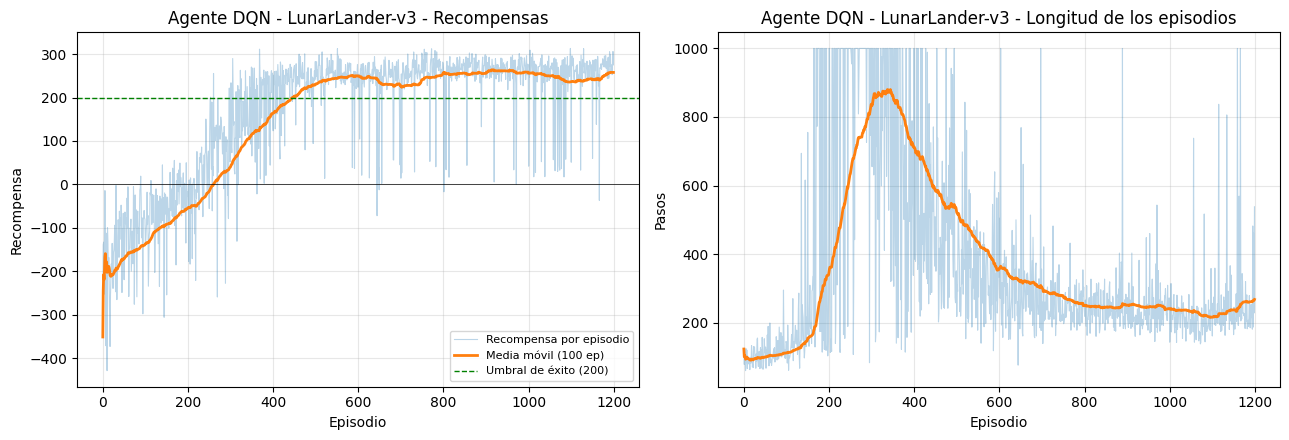

Resultados de los últimos 100 episodios de entrenamiento:
Recompensa promedio: 257.85
Tasa de éxito (R ≥ 200): 95.0%
Epsilon final: 0.010


In [73]:
# Graficar progreso del entrenamiento
graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                "Agente DQN - LunarLander-v3")

# Resultados del final del entrenamiento (todavía con exploración residual)
ultimos = np.array(recompensas_episodios[-100:])
print("Resultados de los últimos 100 episodios de entrenamiento:")
print(f"Recompensa promedio: {ultimos.mean():.2f}")
print(f"Tasa de éxito (R ≥ 200): {(ultimos >= UMBRAL_EXITO).mean():.1%}")
print(f"Epsilon final: {getattr(agente_dqn, 'epsilon', float('nan')):.3f}")

In [74]:
# Opcional: guardar los pesos de la red para no reentrenar en otra sesión, p. ej.
# torch.save(agente_dqn.red_q.state_dict(), 'dqn_lunarlander.pt')
# y recargarlos con agente_dqn.red_q.load_state_dict(torch.load('dqn_lunarlander.pt')).


## 8. Evaluación del agente entrenado

Se evalúan 200 episodios, sin exploración, sobre semillas fijas
(`10000 … 10199`). El agente aleatorio se vuelve a evaluar en la misma celda con
esas mismas semillas, de modo que ambos agentes enfrenten los mismos escenarios
iniciales.

In [75]:
# Evaluar el agente DQN entrenado
env = gym.make('LunarLander-v3')

print("Evaluando agente DQN entrenado (200 episodios, sin exploración)...")
resultados_dqn = evaluar_agente(agente_dqn, env, num_episodios=200, semilla=10000)
imprimir_resultados_evaluacion(resultados_dqn, "Agente DQN entrenado")

print("\nImplementación de referencia para comparar:")
resultados_aleatorio_200 = evaluar_agente(AgenteAleatorio(env.action_space, semilla=SEMILLA), env,
                                          num_episodios=200, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio_200, "Agente aleatorio")

env.close()

Evaluando agente DQN entrenado (200 episodios, sin exploración)...

Agente DQN entrenado - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 92.5%
Recompensa promedio: 260.46
Recompensa mediana:  265.39
Desviación estándar: 37.92
Total de éxitos: 185 / 200

Implementación de referencia para comparar:

Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -183.12
Recompensa mediana:  -149.80
Desviación estándar: 111.95
Total de éxitos: 0 / 200


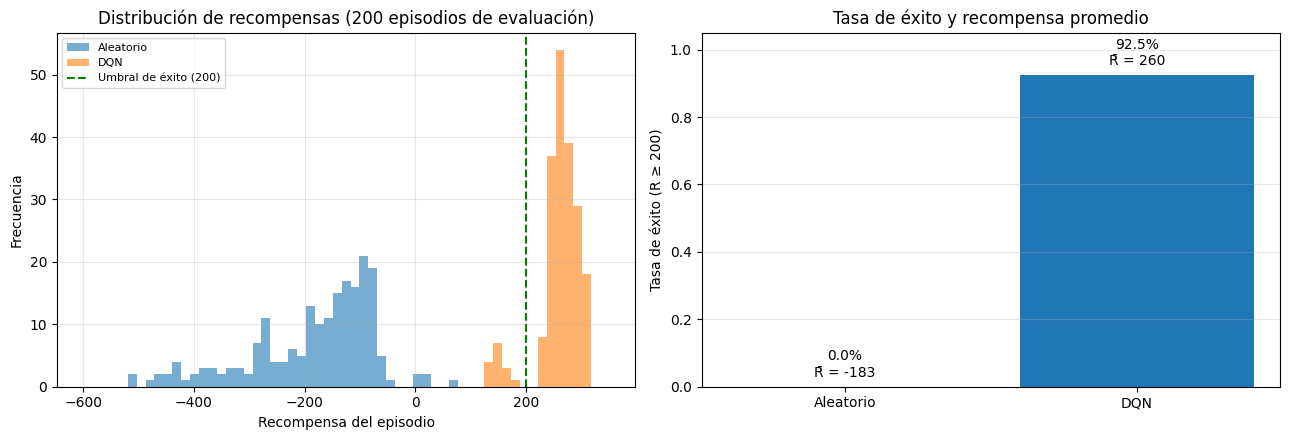

Tasa de éxito DQN:       92.5%
Tasa de éxito Aleatorio: 0.0%
Mejora en recompensa promedio: 443.6 puntos

Desglose de los 200 episodios del DQN:
  R ≥  200:  92.5%
  R ≥  150:  95.0%
  R ≥  100: 100.0%
  R ≥    0: 100.0%
  Episodios que se estrellan (R < -50): 0.0%


In [76]:
# Comparación gráfica: DQN vs. agente aleatorio
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5)) 

bins = np.linspace(-600, 350, 60)
ax1.hist(resultados_aleatorio_200['recompensas_totales'], bins=bins, alpha=0.6, label="Aleatorio")
ax1.hist(resultados_dqn['recompensas_totales'], bins=bins, alpha=0.6, label="DQN")
ax1.axvline(UMBRAL_EXITO, color='green', linestyle='--', label="Umbral de éxito (200)")
ax1.set_title("Distribución de recompensas (200 episodios de evaluación)")
ax1.set_xlabel("Recompensa del episodio")
ax1.set_ylabel("Frecuencia")
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

nombres = ["Aleatorio", "DQN"]
tasas = [resultados_aleatorio_200['tasa_exito'], resultados_dqn['tasa_exito']]
promedios = [resultados_aleatorio_200['recompensa_promedio'], resultados_dqn['recompensa_promedio']]

barras = ax2.bar(nombres, tasas, color=['tab:gray', 'tab:blue'])
ax2.set_ylim(0, 1.05)
ax2.set_ylabel("Tasa de éxito (R ≥ 200)")
ax2.set_title("Tasa de éxito y recompensa promedio")
for barra, tasa, promedio in zip(barras, tasas, promedios):
    ax2.text(barra.get_x() + barra.get_width() / 2, tasa + 0.03,
             f"{tasa:.1%}\nR̄ = {promedio:.0f}", ha='center', fontsize=10)
ax2.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Tasa de éxito DQN:       {resultados_dqn['tasa_exito']:.1%}")
print(f"Tasa de éxito Aleatorio: {resultados_aleatorio_200['tasa_exito']:.1%}")
print(f"Mejora en recompensa promedio: "
      f"{resultados_dqn['recompensa_promedio'] - resultados_aleatorio_200['recompensa_promedio']:.1f} puntos")

# El umbral de 200 es un corte tajante: desglose de la cola de la distribución.
r_dqn = resultados_dqn['recompensas_totales']
print("\nDesglose de los 200 episodios del DQN:")
for corte in (200, 150, 100, 0):
    print(f"  R ≥ {corte:4d}: {(r_dqn >= corte).mean():6.1%}")
print(f"  Episodios que se estrellan (R < -50): {(r_dqn < -50).mean():.1%}")

## 9. Visualización de la política aprendida

Se corren 10 episodios sin exploración sobre semillas sorteadas, sin elegir
los que salieron bien, y se arma un GIF con los diez en una grilla. Cada cuadro
muestra al terminar la recompensa del episodio, en verde si llegó al umbral de éxito
y en rojo si no.

  semilla 20892:  709 pasos, recompensa   259.6
  semilla 27739:  226 pasos, recompensa   253.8
  semilla 26545:  208 pasos, recompensa   251.7
  semilla 24388:  195 pasos, recompensa   250.7
  semilla 24330:  198 pasos, recompensa   302.2
  semilla 28585:  214 pasos, recompensa   303.0
  semilla 20859:  207 pasos, recompensa   239.9
  semilla 26973:  488 pasos, recompensa   295.0
  semilla 22014:  203 pasos, recompensa   268.6
  semilla 20941:  177 pasos, recompensa   249.6

10/10 episodios exitosos, recompensa media 267.4 → aterrizaje_dqn.gif


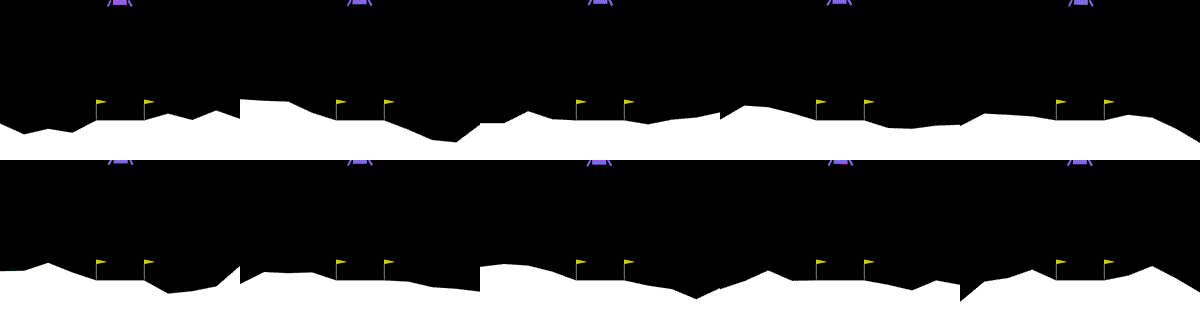

In [77]:
from PIL import Image, ImageDraw
from IPython.display import Image as MostrarImagen, display

ANCHO_CUADRO, ALTO_CUADRO = 240, 160

def _correr_episodio_render(agente, env, semilla, salto):
    """Corre un episodio renderizando y devuelve (cuadros, recompensa, pasos)."""
    estado, _ = env.reset(seed=semilla)
    cuadros, recompensa_total, paso = [], 0.0, 0
    while True:
        if paso % salto == 0:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
        estado, recompensa, terminado, truncado, _ = env.step(agente.elegir_accion(estado, explorar=False))
        recompensa_total += recompensa
        paso += 1
        if terminado or truncado:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
            break
    return cuadros, recompensa_total, paso


def _rotular(cuadro, recompensa, umbral):
    """Escribe la recompensa final sobre el cuadro: verde si es éxito, rojo si no."""
    cuadro = cuadro.copy()
    color = (40, 170, 70) if recompensa >= umbral else (210, 50, 50)
    ImageDraw.Draw(cuadro).text((6, 4), f"R = {recompensa:.0f}", fill=color)
    return cuadro


def grabar_episodios(agente, ruta_gif='aterrizaje_dqn.gif', semillas=range(10_000, 10_010),
                     columnas=5, salto=3, umbral=UMBRAL_EXITO):
    """Corre un episodio sin exploración por semilla y guarda un GIF con todos en
    una grilla. Los episodios que terminan antes quedan quietos en su último cuadro,
    rotulado con la recompensa obtenida."""
    env = gym.make('LunarLander-v3', render_mode='rgb_array')
    episodios = []
    try:
        for semilla in semillas:
            cuadros, recompensa_total, pasos = _correr_episodio_render(agente, env, semilla, salto)
            print(f"  semilla {semilla}: {pasos:4d} pasos, recompensa {recompensa_total:7.1f}")
            cuadros[-1] = _rotular(cuadros[-1], recompensa_total, umbral)
            episodios.append((cuadros, recompensa_total))
    finally:
        env.close()

    filas = -(-len(episodios) // columnas)
    largo = max(len(cuadros) for cuadros, _ in episodios)
    fotogramas = []
    for t in range(largo):
        lienzo = Image.new('RGB', (columnas * ANCHO_CUADRO, filas * ALTO_CUADRO), 'white')
        for i, (cuadros, _) in enumerate(episodios):
            lienzo.paste(cuadros[min(t, len(cuadros) - 1)],
                         ((i % columnas) * ANCHO_CUADRO, (i // columnas) * ALTO_CUADRO))
        fotogramas.append(lienzo)
    fotogramas[0].save(ruta_gif, save_all=True, append_images=fotogramas[1:], duration=50, loop=0)

    recompensas = np.array([r for _, r in episodios])
    print(f"\n{(recompensas >= umbral).sum()}/{len(recompensas)} episodios exitosos, "
          f"recompensa media {recompensas.mean():.1f} → {ruta_gif}")
    return ruta_gif, recompensas


# Semillas sorteadas, no elegidas: el GIF muestra los diez episodios salgan como salgan.
semillas_gif = np.random.default_rng(SEMILLA).integers(20000, 30000, size=10).tolist()
ruta, _ = grabar_episodios(agente_dqn, semillas=semillas_gif)
display(MostrarImagen(filename=ruta))

## 10. Qué aprendió la política

Analicen la política aprendida utilizando cortes con valores fijos en algunas
dimensiones para validar lo aprendido.


127960 estados visitados en 500 episodios; 25 episodios terminaron trabados en el suelo


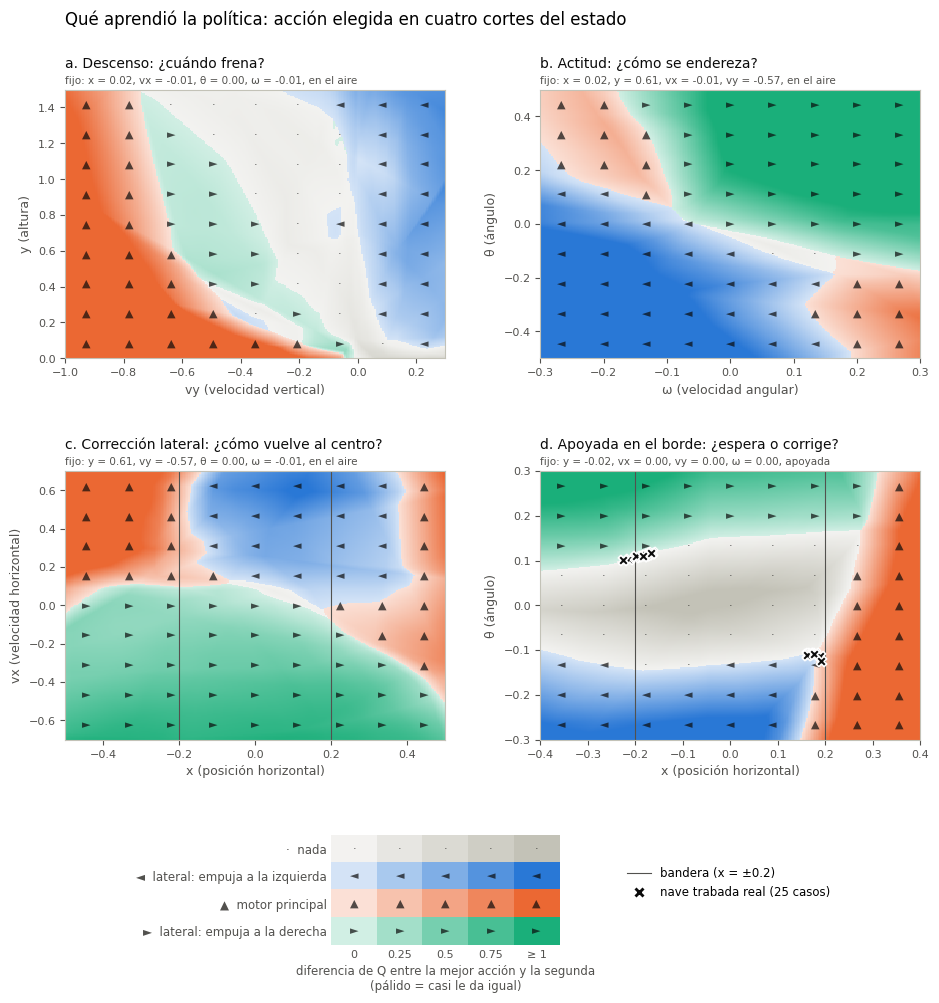

a. Prende el motor principal si cae más rápido que: |vy| > 0.71 a y = 1.2, |vy| > 0.63 a y = 0.6, |vy| > 0.22 a y = 0.1
d. En los 25 estados trabados reales, la diferencia de Q mediana es 0.026; elige: nada 14, lateral: empuja a la izquierda 4, motor principal 1, lateral: empuja a la derecha 6


In [78]:
# TODO 2: cortes de la política
# Un corte fija 6 de las 8 dimensiones del estado y varía las otras 2 en una grilla. En cada punto se le
# pregunta a la red qué acción elige (color y símbolo) y qué tan clara es la elección: la diferencia entre
# el Q de la mejor acción y el de la segunda (intensidad; pálido = casi le da igual). No se simula nada:
# cada punto responde "si la nave estuviera exactamente en este estado, ¿qué haría?".
from matplotlib.lines import Line2D

# Estados visitados por el agente sin exploración, con semillas de diagnóstico (≠ test y GIF)
SEMILLA_DIAGNOSTICO = 40_000
N_EPISODIOS_DIAGNOSTICO = 500

env = gym.make('LunarLander-v3')
visitados, trabados = [], []
for k in range(N_EPISODIOS_DIAGNOSTICO):
    estado, _ = env.reset(seed=SEMILLA_DIAGNOSTICO + k)
    while True:
        visitados.append(estado)
        estado, _, terminado, truncado, _ = env.step(agente_dqn.elegir_accion(estado, explorar=False))
        if terminado or truncado:
            break
    if truncado and (estado[6] or estado[7]):   # llegó a los 1000 pasos apoyada: se trabó sin dormirse
        trabados.append(estado)
env.close()
visitados, trabados = np.array(visitados), np.array(trabados)
en_aire = visitados[(visitados[:, 6] == 0) & (visitados[:, 7] == 0)]
print(f"{len(visitados)} estados visitados en {N_EPISODIOS_DIAGNOSTICO} episodios; "
      f"{len(trabados)} episodios terminaron trabados en el suelo")

# Valores típicos: medianas de los estados visitados. vy depende mucho de la altura, así que a media
# altura se usa la mediana de vy cerca de esa altura. El panel d usa la mediana de las naves trabadas.
tipico_aire = np.median(en_aire, axis=0)
tipico_media_altura = tipico_aire.copy()
tipico_media_altura[3] = np.median(en_aire[np.abs(en_aire[:, 1] - tipico_aire[1]) < 0.1, 3])
tipico_trabado = np.median(trabados, axis=0)


# Corte de la política: acción elegida y diferencia de Q en una grilla de dos dimensiones
def corte_politica(agente, base, eje_x, valores_x, eje_y, valores_y):
    estados = np.tile(np.asarray(base, dtype=np.float32), (len(valores_y), len(valores_x), 1))
    estados[:, :, eje_x] = valores_x[None, :]
    estados[:, :, eje_y] = valores_y[:, None]
    with torch.no_grad():
        q = agente.red_q(torch.as_tensor(estados.reshape(-1, len(base)))).numpy()
    q_ordenado = np.sort(q, axis=1)
    forma = (len(valores_y), len(valores_x))
    return q.argmax(axis=1).reshape(forma), (q_ordenado[:, -1] - q_ordenado[:, -2]).reshape(forma)


# Colores: uno por acción (gris para "nada"); con poca diferencia de Q el color se mezcla con blanco
COLORES = np.array([[0xc3, 0xc2, 0xb7], [0x2a, 0x78, 0xd6], [0xeb, 0x68, 0x34], [0x1b, 0xaf, 0x7a]]) / 255
SIMBOLOS = ['·', '◄', '▲', '►']
NOMBRES_ACCIONES = ['nada', 'lateral: empuja a la izquierda', 'motor principal', 'lateral: empuja a la derecha']
DIFERENCIA_PLENA = 1.0    # diferencia de Q a partir de la cual el color es pleno
INTENSIDAD_MIN = 0.2      # intensidad con diferencia 0 (casi blanco)


def colorear(acciones, diferencia):
    intensidad = INTENSIDAD_MIN + (1 - INTENSIDAD_MIN) * np.clip(diferencia / DIFERENCIA_PLENA, 0, 1)
    return 1 - intensidad[..., None] * (1 - COLORES[acciones])


# Dibujo de un corte: imagen de colores y, encima, el símbolo de la acción en una grilla gruesa
NOMBRES_EJES = ['x (posición horizontal)', 'y (altura)', 'vx (velocidad horizontal)', 'vy (velocidad vertical)',
                'θ (ángulo)', 'ω (velocidad angular)']
NOMBRES_CORTOS = ['x', 'y', 'vx', 'vy', 'θ', 'ω']


def dibujar_corte(ax, agente, titulo, base, eje_x, rango_x, eje_y, rango_y, n_simbolos=9):
    valores_x, valores_y = np.linspace(*rango_x, 241), np.linspace(*rango_y, 241)
    acciones, diferencia = corte_politica(agente, base, eje_x, valores_x, eje_y, valores_y)
    ax.imshow(colorear(acciones, diferencia), origin='lower', aspect='auto', interpolation='nearest',
              extent=[*rango_x, *rango_y])

    # Símbolos en los centros de una grilla gruesa: la acción se lee aunque el color sea pálido
    centros_x = rango_x[0] + (np.arange(n_simbolos) + 0.5) * (rango_x[1] - rango_x[0]) / n_simbolos
    centros_y = rango_y[0] + (np.arange(n_simbolos) + 0.5) * (rango_y[1] - rango_y[0]) / n_simbolos
    acciones_gruesas, _ = corte_politica(agente, base, eje_x, centros_x, eje_y, centros_y)
    for i, cy in enumerate(centros_y):
        for j, cx in enumerate(centros_x):
            ax.text(cx, cy, SIMBOLOS[acciones_gruesas[i, j]], ha='center', va='center', fontsize=8,
                    color='#0b0b0b', alpha=0.7)

    # Títulos: la pregunta del corte y, debajo, los valores fijos
    fijos = [f"{NOMBRES_CORTOS[d]} = {base[d]:.2f}".replace('-0.00', '0.00')
             for d in range(6) if d not in (eje_x, eje_y)]
    patas = 'en el aire' if base[6] + base[7] == 0 else 'apoyada'
    ax.set_title(titulo, loc='left', fontsize=10, color='#0b0b0b', pad=16)
    ax.text(0, 1.015, f"fijo: {', '.join(fijos)}, {patas}", transform=ax.transAxes, fontsize=7.5,
            color='#52514e', va='bottom')
    ax.set_xlabel(NOMBRES_EJES[eje_x], fontsize=9, color='#52514e')
    ax.set_ylabel(NOMBRES_EJES[eje_y], fontsize=9, color='#52514e')
    ax.tick_params(labelsize=8, colors='#52514e')
    for borde in ax.spines.values():
        borde.set_color('#c3c2b7')


# Figura: los 4 cortes. Los rangos cubren los estados visitados (y la frontera de frenado en a)
fig = plt.figure(figsize=(9.5, 10))
grilla = fig.add_gridspec(2, 2, left=0.08, right=0.98, top=0.9, bottom=0.25, hspace=0.42, wspace=0.25)
ejes = [fig.add_subplot(grilla[i // 2, i % 2]) for i in range(4)]

dibujar_corte(ejes[0], agente_dqn, 'a. Descenso: ¿cuándo frena?', tipico_aire,
              3, (-1.0, 0.3), 1, (0.0, 1.5))
dibujar_corte(ejes[1], agente_dqn, 'b. Actitud: ¿cómo se endereza?', tipico_media_altura,
              5, (-0.3, 0.3), 4, (-0.5, 0.5))
dibujar_corte(ejes[2], agente_dqn, 'c. Corrección lateral: ¿cómo vuelve al centro?', tipico_media_altura,
              0, (-0.5, 0.5), 2, (-0.7, 0.7))
dibujar_corte(ejes[3], agente_dqn, 'd. Apoyada en el borde: ¿espera o corrige?', tipico_trabado,
              0, (-0.4, 0.4), 4, (-0.3, 0.3))
for ax in ejes[2:]:
    for x_bandera in (-0.2, 0.2):
        ax.axvline(x_bandera, color='#52514e', lw=0.8)
ejes[3].scatter(trabados[:, 0], trabados[:, 4], marker='X', s=55, color='#0b0b0b', edgecolors='white',
                linewidths=1.2, zorder=3)

# Leyenda de colores: cada fila es una acción y cada columna una diferencia de Q
leyenda = fig.add_axes([0.36, 0.045, 0.24, 0.11])
niveles = np.linspace(0, DIFERENCIA_PLENA, 5)
leyenda.imshow(colorear(np.repeat(np.arange(4)[:, None], len(niveles), axis=1), np.tile(niveles, (4, 1))),
               aspect='auto', interpolation='nearest')
for a in range(4):
    for j in range(len(niveles)):
        leyenda.text(j, a, SIMBOLOS[a], ha='center', va='center', fontsize=8, color='#0b0b0b', alpha=0.7)
leyenda.set_yticks(range(4), [f"{SIMBOLOS[a]}  {NOMBRES_ACCIONES[a]}" for a in range(4)], fontsize=8.5)
leyenda.set_xticks(range(len(niveles)), [f"{v:g}" for v in niveles[:-1]] + [f"≥ {DIFERENCIA_PLENA:g}"],
                   fontsize=8)
leyenda.set_xlabel('diferencia de Q entre la mejor acción y la segunda\n(pálido = casi le da igual)',
                   fontsize=8.5, color='#52514e')
leyenda.tick_params(length=0, colors='#52514e')
for borde in leyenda.spines.values():
    borde.set_visible(False)

# Leyenda de las marcas de los paneles c y d
fig.legend(handles=[Line2D([], [], color='#52514e', lw=0.8, label='bandera (x = ±0.2)'),
                    Line2D([], [], marker='X', ls='none', markersize=8, color='#0b0b0b', markeredgecolor='white',
                           label=f'nave trabada real ({len(trabados)} casos)')],
           loc='lower left', bbox_to_anchor=(0.66, 0.08), fontsize=8.5, frameon=False)

fig.suptitle('Qué aprendió la política: acción elegida en cuatro cortes del estado', fontsize=12, x=0.08, ha='left')
plt.show()

# Resumen numérico de los cortes
# a: a cada altura, la velocidad vertical a partir de la cual deja de frenar (barrido desde la caída más rápida)
vys = np.linspace(-1.5, 0.5, 2001)
umbrales = {}
for y_frenado in (1.2, 0.6, 0.1):
    acciones_vy, _ = corte_politica(agente_dqn, tipico_aire, 3, vys, 1, np.array([y_frenado]))
    umbrales[y_frenado] = vys[np.argmax(acciones_vy[0] != 2)]
print("a. Prende el motor principal si cae más rápido que: "
      + ', '.join(f"|vy| > {-u:.2f} a y = {y}" for y, u in umbrales.items()))
with torch.no_grad():
    q_trabados = agente_dqn.red_q(torch.as_tensor(trabados, dtype=torch.float32)).numpy()
q_ordenado = np.sort(q_trabados, axis=1)
elegidas = np.bincount(q_trabados.argmax(axis=1), minlength=4)
print(f"d. En los {len(trabados)} estados trabados reales, la diferencia de Q mediana es "
      f"{np.median(q_ordenado[:, -1] - q_ordenado[:, -2]):.3f}; elige: "
      + ', '.join(f"{NOMBRES_ACCIONES[a]} {n}" for a, n in enumerate(elegidas)))

## 11. Estudio de ablación

Las secciones anteriores muestran que el DQN completo funciona, pero no *cuánto*
aporta cada una de sus piezas. Una **ablación** responde eso: se reentrena el
agente desde cero desactivando (o degradando) un componente por vez y se mide
cuánto cae el desempeño respecto de la configuración completa.

Comparen el DQN completo contra, como mínimo, tres variantes correspondientes a
quitar características de DQN. Cada configuración se entrena con varias semillas y
se evalúa sobre las mismas semillas de evaluación, sin exploración. Reporten para
cada variante la recompensa de evaluación por semilla y comparen contra el DQN
completo con un test estadístico adecuado.


In [ ]:
# TODO 3: estudio de ablación
# Cada variante saca una pieza del DQN completo (la config 11 del refinamiento); "con bonus" agrega el bonus
# de las banderas. Todas se entrenan con las mismas semillas y se evalúan, sin exploración, en los mismos
# episodios. Cada variante se compara con el completo semilla por semilla: t pareado, corregido por Holm
# porque son 6 comparaciones, y una prueba de permutación como control (ver explicacionTestEstadistica).
from matplotlib.transforms import blended_transform_factory
from scipy import stats

# Parámetros de la ablación
N_EPISODIOS_ABLACION = 1200                                      # igual que el entrenamiento final
SEMILLAS_ABLACION = [300_000 + 2_000 * k for k in range(50)]     # nuevas: ≠ búsqueda (100_000+) y refinamiento (200_000+)
SEMILLA_EVALUACION_ABLACION = 32_000                             # ≠ test, GIF y validaciones (30_000+ y 31_000+)
N_EPISODIOS_EVALUACION_ABLACION = 100
DIR_ABLACION = 'resultados_ablacion'
ALFA = 0.05
LIMITE_DIVERGENCIA = 1000                                        # |Q(s0) − G(s0)| imposible si Q no divergió
Y_MINIMO_GRAFICO = -200                                          # corte del eje y del gráfico

# Variantes: qué cambia respecto del DQN completo
VARIANTES = {
    'completo':   {},
    'sin double': {'usar_double': False},
    'sin target': {'usar_target': False},          # con C = 1, Q' = Q en cada paso: tampoco hay double
    'sin replay': {'usar_replay': False},          # solo las últimas tam_batch transiciones
    'sin huber':  {'usar_huber': False},           # MSE
    'con bonus':  {'usar_bonus_banderas': True},
}
# Comparaciones: cada variante contra el completo, y sin target contra sin double para aislar el target
COMPARACIONES = [(variante, 'completo') for variante in VARIANTES if variante != 'completo']
COMPARACIONES.append(('sin target', 'sin double'))


# Evaluación con detalle: como evaluar_agente (sin exploración, semillas semilla + i), pero además guarda
# cómo terminó cada episodio y la sobreestimación de Q: lo que predice la red contra el retorno descontado
# que realmente obtuvo. Con el bonus, Q aprendió la recompensa con el bonus, así que el retorno lo incluye.
def evaluar_con_detalle(agente, env, num_episodios, semilla):
    recompensas, finales, sobre_inicio, sobre_estados = [], [], [], []
    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=semilla + episodio)
        q_elegidas, recompensas_q, recompensa_total = [], [], 0.0
        while True:
            accion = agente.elegir_accion(estado, explorar=False)
            with torch.no_grad():
                q_elegidas.append(float(agente.red_q(torch.as_tensor(estado, dtype=torch.float32))[accion]))
            siguiente_estado, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa
            bonus = (agente._potencial_banderas(siguiente_estado) - agente._potencial_banderas(estado)
                     if agente.usar_bonus_banderas else 0.0)
            recompensas_q.append(recompensa + bonus)
            estado = siguiente_estado
            if terminado or truncado:
                break

        # Retorno descontado desde cada paso: G_t = r_t + γ·G_{t+1}. Si se truncó, falta el final del
        # retorno, así que en los estados se descartan los últimos 300 pasos (γ^300 ≈ 0.05)
        retornos = np.zeros(len(recompensas_q))
        g = 0.0
        for t in reversed(range(len(recompensas_q))):
            g = recompensas_q[t] + agente.gamma * g
            retornos[t] = g
        validos = len(retornos) if terminado else max(0, len(retornos) - 300)
        sobre_inicio.append(q_elegidas[0] - retornos[0])
        sobre_estados.extend(np.array(q_elegidas[:validos]) - retornos[:validos])

        # Cómo terminó: el último paso da +100 si se durmió apoyada y −100 si chocó o salió de la pantalla
        recompensas.append(recompensa_total)
        if terminado:
            finales.append('aterrizaje' if recompensa > 0 else 'choque')
        else:
            finales.append('trabada' if estado[6] or estado[7] else 'flotando')

    return {'recompensas': [float(r) for r in recompensas], 'finales': finales,
            'sobreestimacion_inicio': float(np.mean(sobre_inicio)),
            'sobreestimacion_estados': float(np.mean(sobre_estados))}


# Una corrida: entrenar una variante con una semilla y evaluarla
def correr_variante(variante, semilla):
    ruta = os.path.join(DIR_ABLACION, f"{variante.replace(' ', '_')}_semilla{semilla}.json")
    ruta_pesos = ruta.replace('.json', '.pt')
    descripcion = {'variante': variante, 'cambios': VARIANTES[variante], 'config': mejor_config, 'semilla': semilla,
                   'n_episodios': N_EPISODIOS_ABLACION, 'semilla_evaluacion': SEMILLA_EVALUACION_ABLACION,
                   'n_episodios_evaluacion': N_EPISODIOS_EVALUACION_ABLACION}

    # Carga de resultados: si la corrida ya está en disco con la misma descripción, no se reentrena
    if os.path.exists(ruta) and os.path.exists(ruta_pesos):
        with open(ruta) as f:
            guardado = json.load(f)
        if all(guardado.get(clave) == valor for clave, valor in descripcion.items()):
            return guardado

    torch.set_num_threads(1)   # un hilo por proceso para que las corridas paralelas no compitan

    # Entrenamiento: igual que el agente principal, salvo por los cambios de la variante
    t_inicio = time.time()
    env = gym.make('LunarLander-v3')
    decaimiento = 0.01 ** (1 / (mejor_config['frac_exploracion'] * N_EPISODIOS_ABLACION))   # ε: 1.0 → 0.01
    agente = AgenteDQN(env.observation_space, env.action_space, semilla=semilla,
                       lr=mejor_config['lr'], tam_batch=mejor_config['tam_batch'],
                       frec_target=mejor_config['frec_target'], tam_oculta=mejor_config['tam_oculta'],
                       delta_huber=mejor_config['delta_huber'], decaimiento_epsilon=decaimiento,
                       **VARIANTES[variante])
    recompensas_entrenamiento, _ = entrenar_agente(agente, env, num_episodios=N_EPISODIOS_ABLACION,
                                                   semilla=semilla, verbose=False)

    # Evaluación: sin exploración y con las mismas semillas para todas las corridas
    evaluacion = evaluar_con_detalle(agente, env, N_EPISODIOS_EVALUACION_ABLACION, SEMILLA_EVALUACION_ABLACION)
    env.close()
    resultado = {**descripcion, **evaluacion,
                 'recompensas_entrenamiento': [float(r) for r in recompensas_entrenamiento],
                 'segundos': time.time() - t_inicio}

    # Guardado del resultado y de los pesos de la red (para re-analizar sin reentrenar)
    torch.save(agente.red_q.state_dict(), ruta_pesos)
    with open(ruta, 'w') as f:
        json.dump(resultado, f)
    return resultado


# Ejecución en paralelo de todas las corridas (semilla × variante). Va semilla por semilla: si se corta,
# lo terminado son pares completos, y al volver a ejecutar se retoma desde el disco.
os.makedirs(DIR_ABLACION, exist_ok=True)
t_ablacion = time.time()
corridas_ablacion = Parallel(n_jobs=N_PROCESOS, verbose=5)(
    delayed(correr_variante)(variante, semilla) for semilla in SEMILLAS_ABLACION for variante in VARIANTES)
print(f"Ablación terminada en {(time.time() - t_ablacion) / 60:.1f} min "
      f"({len(corridas_ablacion)} corridas, resultados en '{DIR_ABLACION}/')")


# Métricas por semilla: una fila por semilla y una columna por variante
corridas = {(c['variante'], c['semilla']): c for c in corridas_ablacion}


def tabla_por_semilla(metrica):
    return pd.DataFrame({variante: [metrica(corridas[variante, semilla]) for semilla in SEMILLAS_ABLACION]
                         for variante in VARIANTES}, index=pd.Index(SEMILLAS_ABLACION, name='semilla'))


def porcentaje_final(final):
    return tabla_por_semilla(lambda c: 100 * c['finales'].count(final) / len(c['finales']))


recompensa = tabla_por_semilla(lambda c: np.mean(c['recompensas']))                         # métrica principal
exito = tabla_por_semilla(lambda c: 100 * np.mean(np.array(c['recompensas']) >= UMBRAL_EXITO))
trabadas = porcentaje_final('trabada')
sobreestimacion = tabla_por_semilla(lambda c: c['sobreestimacion_inicio'])
print(f"Recompensa de evaluación por semilla (media de los {N_EPISODIOS_EVALUACION_ABLACION} episodios):")
display(recompensa.round(1))

# Resumen por variante: media ± desvío entre las semillas. La sobreestimación va con la mediana, porque
# una semilla en la que Q divergió domina la media
resumen_ablacion = pd.DataFrame({
    'recompensa': [f"{recompensa[v].mean():.1f} ± {recompensa[v].std():.1f}" for v in VARIANTES],
    'éxito (%)': exito.mean().round(1),
    **{f'{final} (%)': porcentaje_final(final).mean().round(1)
       for final in ['aterrizaje', 'choque', 'trabada', 'flotando']},
    'Q(s0) − G(s0) (mediana)': sobreestimacion.median().round(1),
    'Q − G en los estados (mediana)': tabla_por_semilla(lambda c: c['sobreestimacion_estados']).median().round(1),
}, index=list(VARIANTES))
print(f"Resumen por variante ({len(SEMILLAS_ABLACION)} semillas, {N_EPISODIOS_EVALUACION_ABLACION} episodios "
      f"de evaluación cada una):")
display(resumen_ablacion)

# Semillas en las que Q divergió: la red predice retornos imposibles (en LunarLander |G| no pasa de unos cientos)
divergentes = [(variante, semilla) for variante in VARIANTES for semilla in SEMILLAS_ABLACION
               if abs(sobreestimacion.loc[semilla, variante]) > LIMITE_DIVERGENCIA]
print(f"Semillas en las que Q divergió (|Q(s0) − G(s0)| > {LIMITE_DIVERGENCIA}): {len(divergentes)}")
for variante, semilla in divergentes:
    print(f"  {variante}, semilla {semilla}: Q(s0) − G(s0) = {sobreestimacion.loc[semilla, variante]:.3g}, "
          f"recompensa {recompensa.loc[semilla, variante]:.1f} (domina la media y el IC de su Q(s0) − G(s0))")


# Prueba de permutación pareada (control del t): si la variante no importara, el signo de cada diferencia
# sería al azar. Se invierten signos al azar y se cuenta qué tan seguido la media queda tan lejos de 0
# como la observada.
rng_permutacion = np.random.default_rng(SEMILLA)


def permutacion_pareada(d, n_permutaciones=200_000):
    signos = rng_permutacion.choice(np.array([-1, 1], dtype=np.int8), size=(n_permutaciones, len(d)))
    medias = signos @ d / len(d)
    return (np.sum(np.abs(medias) >= abs(d.mean()) - 1e-9) + 1) / (n_permutaciones + 1)


# Corrección de Holm: el menor p se multiplica por m, el siguiente por m − 1, etc., sin que bajen
def holm(p):
    orden = np.argsort(p)
    ajustados, maximo = np.empty(len(p)), 0.0
    for i, j in enumerate(orden):
        maximo = max(maximo, min(1.0, (len(p) - i) * p[j]))
        ajustados[j] = maximo
    return ajustados


# Comparación pareada de una métrica: diferencia media (variante − referencia, misma semilla), IC 95 % y
# p del t pareado. Si las diferencias son todas iguales (p. ej. todas 0), el t no está definido.
def comparar(tabla, variante, referencia):
    d = (tabla[variante] - tabla[referencia]).to_numpy()
    error = d.std(ddof=1) / np.sqrt(len(d))
    ic = stats.t.interval(1 - ALFA, len(d) - 1, loc=d.mean(), scale=error) if error > 0 else (d.mean(), d.mean())
    p = stats.ttest_rel(tabla[variante], tabla[referencia]).pvalue if error > 0 else np.nan
    return d, ic, p


def formato_p(p):
    return '—' if np.isnan(p) else '< 0.0001' if p < 1e-4 else f'{p:.4f}'


# Test principal: recompensa de evaluación, t pareado con Holm sobre las 6 comparaciones, y la permutación
# como control (también con Holm). Concluyente si los dos pasan Holm; indicio si alguno da p < α sin
# corregir; si no, sin efecto detectable.
filas = []
for variante, referencia in COMPARACIONES:
    d, ic, p = comparar(recompensa, variante, referencia)
    filas.append({'comparación': f'{variante} − {referencia}', 'diferencia': d.mean(),
                  'IC 95 %': f'[{ic[0]:+.1f}, {ic[1]:+.1f}]', 'p': p, 'p permutación': permutacion_pareada(d)})
tests_ablacion = pd.DataFrame(filas).set_index('comparación')
tests_ablacion['p Holm'] = holm(tests_ablacion['p'].to_numpy())
tests_ablacion['p permutación Holm'] = holm(tests_ablacion['p permutación'].to_numpy())
tests_ablacion['nivel'] = [
    'concluyente' if f['p Holm'] < ALFA and f['p permutación Holm'] < ALFA
    else 'indicio' if f['p'] < ALFA or f['p permutación'] < ALFA
    else 'sin efecto detectable'
    for _, f in tests_ablacion.iterrows()]
tabla_tests = tests_ablacion[['diferencia', 'IC 95 %', 'p', 'p Holm', 'p permutación', 'p permutación Holm', 'nivel']].copy()
tabla_tests['diferencia'] = tabla_tests['diferencia'].map('{:+.1f}'.format)
for columna in ['p', 'p Holm', 'p permutación', 'p permutación Holm']:
    tabla_tests[columna] = tabla_tests[columna].map(formato_p)
print("Test principal: recompensa de evaluación, t pareado (bilateral) con corrección de Holm:")
display(tabla_tests)

# Métricas secundarias: la misma comparación pareada, fuera de Holm (sirven para explicar el resultado)
secundarias = {'éxito (puntos de %)': exito, 'trabadas (puntos de %)': trabadas, 'Q(s0) − G(s0)': sobreestimacion}
filas = []
for variante, referencia in COMPARACIONES:
    fila = {'comparación': f'{variante} − {referencia}'}
    for nombre, tabla in secundarias.items():
        d, ic, p = comparar(tabla, variante, referencia)
        fila[nombre] = f'{d.mean():+.1f} [{ic[0]:+.1f}, {ic[1]:+.1f}], p = {formato_p(p)}'
    filas.append(fila)
print("Métricas secundarias: diferencia [IC 95 %] y p del t pareado, sin corrección:")
display(pd.DataFrame(filas).set_index('comparación'))


# Gráfico: recompensa de evaluación de cada semilla (puntos), con la media y su IC 95 % (en negro). Arriba
# de cada variante, la diferencia con el completo [IC 95 %] y el p de Holm. El eje y se corta en
# Y_MINIMO_GRAFICO para que no lo estire una semilla aislada: las que quedan abajo se marcan en el borde
# con un triángulo y su valor (la media y el IC sí las incluyen)
fig, ax = plt.subplots(figsize=(10, 5.5))
rng_dispersion = np.random.default_rng(SEMILLA)    # corrimiento horizontal de los puntos, solo visual
for i, variante in enumerate(VARIANTES):
    valores = recompensa[variante].to_numpy()
    x = i - 0.08 + rng_dispersion.uniform(-0.15, 0.15, len(valores))
    adentro = valores >= Y_MINIMO_GRAFICO
    ax.scatter(x[adentro], valores[adentro], s=16, color='#2a78d6', alpha=0.55, linewidths=0)
    for x_afuera, valor, semilla in zip(x[~adentro], valores[~adentro], recompensa.index[~adentro]):
        ax.scatter(x_afuera, Y_MINIMO_GRAFICO + 8, marker='v', s=30, color='#2a78d6', linewidths=0)
        nota = ', Q divergió' if (variante, semilla) in divergentes else ''
        ax.text(x_afuera + 0.06, Y_MINIMO_GRAFICO + 8, f'{valor:.0f} (semilla {semilla}{nota})', va='center',
                fontsize=7.5, color='#52514e')
    error = stats.t.ppf(1 - ALFA / 2, len(valores) - 1) * valores.std(ddof=1) / np.sqrt(len(valores))
    ax.errorbar(i + 0.2, valores.mean(), yerr=error, fmt='o', color='#0b0b0b', markersize=5, capsize=4,
                linewidth=1.5)
ax.axhline(UMBRAL_EXITO, color='#898781', linestyle='--', linewidth=0.8, zorder=0)
ax.text(len(VARIANTES) - 0.55, UMBRAL_EXITO, f'umbral de éxito ({UMBRAL_EXITO:.0f})', ha='right', va='bottom',
        fontsize=8, color='#52514e')

arriba = blended_transform_factory(ax.transData, ax.transAxes)
for i, variante in enumerate(VARIANTES):
    if variante == 'completo':
        texto = 'referencia'
    else:
        fila = tests_ablacion.loc[f'{variante} − completo']
        texto = f"{fila['diferencia']:+.1f} {fila['IC 95 %']}\np Holm {formato_p(fila['p Holm'])}"
    ax.text(i, 1.02, texto, transform=arriba, ha='center', va='bottom', fontsize=8, color='#0b0b0b')

ax.set_xticks(range(len(VARIANTES)), list(VARIANTES), fontsize=9)
ax.set_xlim(-0.5, len(VARIANTES) - 0.5)
ax.set_ylim(bottom=Y_MINIMO_GRAFICO)
ax.set_ylabel(f'recompensa media en {N_EPISODIOS_EVALUACION_ABLACION} episodios', fontsize=9, color='#52514e')
ax.tick_params(labelsize=8, colors='#52514e')
ax.grid(axis='y', color='#e5e4dd', linewidth=0.6)
ax.set_axisbelow(True)
for borde in ax.spines.values():
    borde.set_color('#c3c2b7')
ax.set_title(f'Ablación: recompensa de evaluación de cada semilla ({len(SEMILLAS_ABLACION)} por variante)\n'
             'puntos: una semilla; en negro: media e IC 95 %; arriba: diferencia con el completo y p de Holm',
             loc='left', fontsize=10, color='#0b0b0b', pad=40)
plt.tight_layout()
plt.show()